# PharmaML — The Complete PK/PD Workflow (Zero to One Hundred)

One notebook, every stage of a pharmacokinetic / pharmacodynamic analysis,
in the order you would actually run it — the third notebook of the trilogy
(after the ML and the docking workflow), and the one the legacy rar archive
never had: it shipped ~30 model-training scripts and a docking folder with
**not one line of pharma code**. AUCs, half-lives and dose adjustments lived
in spreadsheets beside the project, out of version control. This notebook
brings them into the codebase.

| § | Stage | Toolkit |
|---|---|---|
| 0 | **Setup** — imports, scratch directory | — |
| 1 | **Data entry** — import *your own* profile CSV/Excel | `pharmaml.utils` |
| 2 | Non-compartmental analysis — AUC/AUMC/MRT/Cmax/Tmax/t½ | `pharmaml.pharma` |
| 3 | AUC math exposed — linear vs log trapezoid, AUMC, MRT | `pharmaml.pharma` |
| 4 | Terminal half-life & derived parameters — ke, CL, Vd | `pharmaml.pharma` |
| 5 | Analytic 1-compartment checks — Tmax/Cmax closed forms | `pharmaml.pharma` |
| 6 | IV routes — bolus decay, infusion steady state | `pharmaml.pharma` |
| 7 | Repeated dosing — accumulation ratio, steady state | `pharmaml.viz` |
| 8 | PD — the Emax family, target-effect inversion | `pharmaml.pharma` |
| 9 | Dosage design — maintenance, loading, size scaling | `pharmaml.pharma` |
| 10 | Patient-specific adjustments — renal function, TDM | `pharmaml.pharma` |
| 11 | Units & molar mass — the unit discipline in one place | `pharmaml.pharma` |
| 12 | Publish — one-click HTML report + csv/tsv/md/json/html | `pharmaml.viz` |

**Setup** — from the inner `pharma-ml-toolkit/` package root, install the local
reports extra:

```bash
python -m pip install -e '.[reports]'
```

Every number below comes from the shipped fixed-seed demo profile
(`examples/data/pk_profile.csv`), so the notebook runs offline and stays
fully reproducible; replace it in §1 with your own CSV and re-run all cells.


## 0 · Setup

Imports, display options and a scratch directory — every artifact this
notebook writes (the imported profile, the exported tables, the final
report) lands under `WORK`. Nothing else on your machine is touched.


In [1]:
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

from pharmaml import __version__

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 110)

# Scratch directory for this run's artifacts (use any path you like).
WORK = Path(tempfile.mkdtemp(prefix="pk_workflow_"))

# The shipped demo inventory: the demo profile loads from examples/data/
# instead of being simulated inline.
DATA_DIR = Path("data")

print(f"pharmaml {__version__}")
print(f"artifacts -> {WORK}")


pharmaml 1.2.246
artifacts -> /tmp/pk_workflow__hy_4dun


## 1 · Data entry — bring your own file

`read_table` is the single entry point for **your** data: any
CSV/TSV/TXT/Excel file, delimiter sniffed automatically. `require_columns`
then fails loudly — not mysteriously three sections later — if the columns
the analysis needs are missing, and `validate_concentration_series` checks
the pairing itself (equal length, strictly ascending times, non-negative
concentrations: the assumptions every trapezoid silently makes).

CLI equivalent:

```bash
pharmaml pharma pk --data profile.csv --time time_h --conc conc_ng_ml
```

The demo profile below ships as `examples/data/pk_profile.csv` — a
one-compartment oral simulation with realistic 5 % assay noise, generated
once with seed 7 (`tools/build_example_data.py` keeps the generator).
**Swap it for your own file and every cell below runs unchanged.**


In [2]:
# --- DEMO DATA ---------------------------------------------------------
# A one-compartment oral concentration-time profile: ka = 1.2/h,
# ke = 0.35/h, a 250 mg dose into Vd = 35 L with F = 0.9, plus realistic
# 5% assay noise on every sample.  Generated once with seed 7 by
# tools/build_example_data.py and shipped as examples/data/pk_profile.csv.
# (In your project: set PROFILE_CSV to your own file.)
PROFILE_CSV = DATA_DIR / "pk_profile.csv"   # <- replace with your own file

profile = pd.read_csv(PROFILE_CSV)
print(f"demo profile: {PROFILE_CSV}  ({len(profile)} samples)")


demo profile: data/pk_profile.csv  (49 samples)


In [3]:
# --- THE ACTUAL IMPORT (works unchanged for your file) -----------------
from pharmaml.utils import read_table, require_columns

frame = read_table(PROFILE_CSV)
require_columns(frame, ["time_h", "conc_ng_ml"])   # loud failure if renamed

times = frame["time_h"].to_numpy()
conc = frame["conc_ng_ml"].to_numpy()

print(f"{PROFILE_CSV.name}: {len(frame)} samples, "
      f"t = {times.min():g}–{times.max():g} h, peak {conc.max():.2f}")
frame.head(6)


pk_profile.csv: 49 samples, t = 0–24 h, peak 3.70


,time_h,conc_ng_ml
0,0.0,0.000000
1,0.5,2.677191
2,1.0,3.611767
3,1.5,3.696281
4,2.0,3.599763
5,2.5,3.166256


In [4]:
from pharmaml.exceptions import DataValidationError
from pharmaml.pharma.pk import validate_concentration_series

# The guard every PK function runs first: paired, finite, ascending,
# non-negative. It returns the cleaned float arrays. (Strict mode --
# required by log-trapezoids -- would also reject the exactly-zero t = 0
# sample; §3 handles that by subsetting the positive tail.)
t_clean, c_clean = validate_concentration_series(
    times, conc, require_positive_conc=False
)
print(f"validated: {len(t_clean)} paired samples, all concentrations >= 0")

# ...and what it does with a bad series -- here a negative concentration,
# the classic LC-MS artifact reported below the quantification limit:
bad = conc.copy()
bad[4] = -0.25
try:
    validate_concentration_series(times, bad, require_positive_conc=False)
except DataValidationError as exc:
    print(f"rejected: {exc}")


validated: 49 paired samples, all concentrations >= 0
rejected: concentrations must be non-negative


## 2 · Non-compartmental analysis

NCA is the honest default of pharmacokinetics: no compartments, no fitted
parameters — just the areas, moments and extremes of the curve you
measured. `nca_summary` returns the standard six: AUC, AUMC, MRT, Cmax,
Tmax and the terminal half-life (log-linear slope of the last positive
samples). Anything the curve cannot define (a blank curve's MRT, say)
comes back as `n/a`, not as a crash.

CLI equivalent:

```bash
pharmaml pharma pk --data profile.csv --time time_h --conc conc_ng_ml --out nca.json
```


In [5]:
from pharmaml.pharma.pk import nca_summary

summary = nca_summary(times, conc)

print("=== Non-compartmental analysis (single 250 mg oral dose) ===")
for key, value in summary.as_dict().items():
    shown = "n/a" if not np.isfinite(value) else f"{value:.3f}"
    print(f"{key:<18} {shown}")


=== Non-compartmental analysis (single 250 mg oral dose) ===
AUC                17.961
AUMC               66.583
MRT                3.707
Cmax               3.696
Tmax               1.500
t_half_terminal    1.620


In [6]:
from pharmaml.viz import metrics_to_dataframe

# The same summary as a tidy metric|value table -- exactly what §12
# publishes as csv/markdown and embeds in the HTML report.
nca_frame = metrics_to_dataframe(summary)
nca_frame


,metric,value
0,AUC,17.960737
1,AUMC,66.582635
2,MRT,3.707122
3,Cmax,3.696281
4,Tmax,1.500000
5,t_half_terminal,1.620369


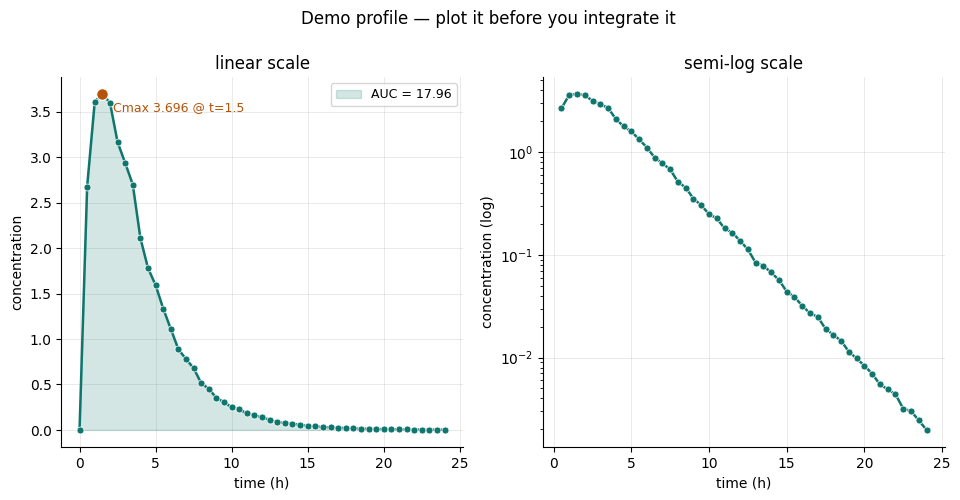

In [7]:
from pharmaml.viz import plot_concentration_profile

# Plot before you trust: linear + semi-log panels, the trapezoid AUC
# shaded under the curve. §12 re-plots this with the NCA annotations on.
fig_profile = plot_concentration_profile(
    times, conc,
    title="Demo profile — plot it before you integrate it",
)


## 3 · AUC math exposed

Every NCA number in §2 is one trapezoid sum away. The **linear** trapezoid
is the safe default (zero concentrations are fine); the **logarithmic**
trapezoid is more accurate while the curve decays exponentially — but it
demands strictly positive concentrations, so the exactly-zero t = 0 sample
has to stay out of it. AUMC integrates `t·C(t)` and MRT is simply
`AUMC/AUC`: the average time a drug molecule spends in the body.


In [8]:
from pharmaml.pharma.pk import auc_trapezoid

auc_linear = auc_trapezoid(times, conc)                 # safe with zeros
positive = conc > 0                                     # the t=0 sample is 0
auc_log = auc_trapezoid(times[positive], conc[positive], method="log")

print(f"AUC linear        {auc_linear:8.4f}   (all {len(times)} samples)")
print(f"AUC log           {auc_log:8.4f}   ({int(positive.sum())} positive samples)")
print(f"AUC nca_summary   {summary.auc:8.4f}   (same linear rule)")
print(f"linear - log      {auc_linear - auc_log:+8.4f}   "
      "(the linear rule overestimates a decaying curve)")


AUC linear         17.9607   (all 49 samples)
AUC log            17.2536   (48 positive samples)
AUC nca_summary    17.9607   (same linear rule)
linear - log       +0.7071   (the linear rule overestimates a decaying curve)


In [9]:
from pharmaml.pharma.pk import aucm_trapezoid, mrt

aucm = aucm_trapezoid(times, conc)
mrt_value = mrt(times, conc)

print(f"AUMC  {aucm:8.4f} ng·h²/mL   ∫ t·C(t) dt, trapezoid")
print(f"MRT   {mrt_value:8.4f} h          = AUMC/AUC = {aucm / summary.auc:.4f}")
print(f"      (identity holds: MRT is the first moment normalised by AUC)")


AUMC   66.5826 ng·h²/mL   ∫ t·C(t) dt, trapezoid
MRT     3.7071 h          = AUMC/AUC = 3.7071
      (identity holds: MRT is the first moment normalised by AUC)


## 4 · Terminal half-life & derived parameters

`half_life` and `elimination_rate_constant` are the same constant in two
costumes (t½ = ln2/ke) — use whichever your data hands you. The
interesting part is what the AUC buys: with the dose and bioavailability
known, clearance follows (`CL = F·Dose/AUC`); leave F out and you get the
*apparent* clearance CL/F. The volume then comes from `Vd = CL/ke`.

One honesty note before the numbers: the terminal slope here comes from
the **last positive samples** of a noisy curve, so the NCA half-life
(≈ 1.62 h) undershoots the simulated truth (ln2/0.35 ≈ 1.98 h). That is
what two noisy points buy you — commercial NCA software lets you pick the
terminal range by hand for exactly this reason.


In [10]:
from pharmaml.pharma.pk import elimination_rate_constant, half_life

ke = elimination_rate_constant(summary.half_life_terminal)
t_half_back = half_life(ke)

print(f"terminal t½ (NCA)   {summary.half_life_terminal:.4f} h")
print(f"ke = ln2/t½         {ke:.4f} 1/h")
print(f"t½ = ln2/ke         {t_half_back:.4f} h    (round trip, exact)")
print(f"simulated truth     {np.log(2) / 0.35:.4f} h    (ke = 0.35)")


terminal t½ (NCA)   1.6204 h
ke = ln2/t½         0.4278 1/h
t½ = ln2/ke         1.6204 h    (round trip, exact)
simulated truth     1.9804 h    (ke = 0.35)


In [11]:
from pharmaml.pharma.pk import clearance, vd_from_dose_auc, volume_of_distribution

DOSE, F = 250.0, 0.9    # the simulation's inputs -- in a real study, yours

cl = clearance(dose=DOSE, auc=summary.auc, f=F)   # CL   = F·Dose/AUC
cl_f = clearance(dose=DOSE, auc=summary.auc)      # CL/F = Dose/AUC (F unknown)
dose_auc_ratio = vd_from_dose_auc(DOSE, summary.auc)
vd_estimate = volume_of_distribution(cl, ke)      # Vd = CL/ke

print(f"CL        {cl:7.2f} L/h   (simulated truth: ke·Vd = {0.35 * 35.0:.2f} L/h)")
print(f"CL/F      {cl_f:7.2f} L/h   (ignoring F overstates clearance)")
print(f"Vd        {vd_estimate:7.2f} L     (simulated truth: 35 L)")
print(f"Dose/AUC  {dose_auc_ratio:7.2f}       -- CL/F again, not a volume;")
print(f"                    the honest volume route is CL/ke = {vd_estimate:.2f} L")


CL          12.53 L/h   (simulated truth: ke·Vd = 12.25 L/h)
CL/F        13.92 L/h   (ignoring F overstates clearance)
Vd          29.29 L     (simulated truth: 35 L)
Dose/AUC    13.92       -- CL/F again, not a volume;
                    the honest volume route is CL/ke = 29.29 L


## 5 · Analytic 1-compartment checks

The demo data was simulated from the textbook one-compartment oral model,
so the closed forms should reproduce the NCA numbers — a sanity check you
only get with simulated data, and a clean illustration of how much a
trapezoid over 49 noisy points smears the truth (the 0.5 h sampling grid
alone pins NCA Tmax to a multiple of 0.5).

`oral_tmax` refuses `ka <= ke` (flip-flop kinetics) instead of silently
returning a negative time.


In [12]:
from pharmaml.pharma.pk import oral_cmax, oral_tmax

t_max_analytic = oral_tmax(ka=1.2, ke=0.35)
c_max_analytic = oral_cmax(dose=250.0, ka=1.2, ke=0.35, vd=35.0, f=0.9)

pd.DataFrame(
    {
        "parameter": ["Tmax (h)", "Cmax (ng/mL)"],
        "NCA (measured)": [summary.t_max, summary.c_max],
        "analytic 1-cmt": [t_max_analytic, c_max_analytic],
    }
)


,parameter,NCA (measured),analytic 1-cmt
0,Tmax (h),1.500000,1.449581
1,Cmax (ng/mL),3.696281,3.870559


## 6 · IV routes

The same one-compartment engine covers the IV family: a bolus is a pure
exponential decay from `C0 = Dose/Vd`, and a constant infusion settles at
`Css = rate/CL` — two one-liners that bracket every IV regimen between
them.


In [13]:
from pharmaml.pharma.pk import iv_bolus_concentration

# A 250 mg IV bolus straight into Vd = 35 L: C0 = 7.14, decaying with ke.
iv_grid = np.array([0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0, 12.0])
iv_conc = iv_bolus_concentration(c0=250.0 / 35.0, ke=0.35, t=iv_grid)

print(f"C0 = dose/Vd = {250.0 / 35.0:.3f}, half-life {np.log(2) / 0.35:.2f} h")
iv_frame = pd.DataFrame({"time_h": iv_grid, "conc": np.round(iv_conc, 4)})
iv_frame


C0 = dose/Vd = 7.143, half-life 1.98 h


,time_h,conc
0,0.00,7.1429
1,0.25,6.5444
2,0.50,5.9961
3,1.00,5.0335
4,2.00,3.5470
5,4.00,1.7614
6,8.00,0.4344
7,12.00,0.1071


In [14]:
from pharmaml.pharma.pk import iv_infusion_steady_state

# Css = rate/CL: with the §4 clearance, a 150 mg/h infusion settles at...
rate = 150.0
css = iv_infusion_steady_state(rate=rate, clearance_=cl)
print(f"infusion {rate:g} mg/h at CL = {cl:.2f} L/h -> Css = {css:.2f} mg/L")
print(f"check: rate/CL = {rate / cl:.2f}")


infusion 150 mg/h at CL = 12.53 L/h -> Css = 11.97 mg/L
check: rate/CL = 11.97


## 7 · Repeated dosing & accumulation

Dose every τ hours and the previous dose's tail stacks onto the next: the
accumulation ratio `R = 1/(1 − e^(−ke·τ))` says by how much, and steady
state is practically reached after ~5 half-lives. The figure shows the
one-compartment superposition of six doses with the Cmax,ss / Cmin,ss
envelope drawn on top.

With our t½ ≈ 1.6 h drug, a 12 h interval barely accumulates (R ≈ 1.006) —
an instructive corner: accumulation only matters when τ approaches t½.
Shorten τ to 2 h in the cell below to watch the envelope climb.


In [15]:
from pharmaml.pharma.pk import accumulation_ratio

taus = [2.0, 6.0, 12.0, 24.0]   # candidate intervals for a t½ ≈ 1.6 h drug
ratio_frame = pd.DataFrame(
    {
        "tau_h": taus,
        "R_accumulation": [
            accumulation_ratio(tau, summary.half_life_terminal) for tau in taus
        ],
    }
)
ratio_frame


,tau_h,R_accumulation
0,2.0,1.739289
1,6.0,1.083182
2,12.0,1.005932
3,24.0,1.000035


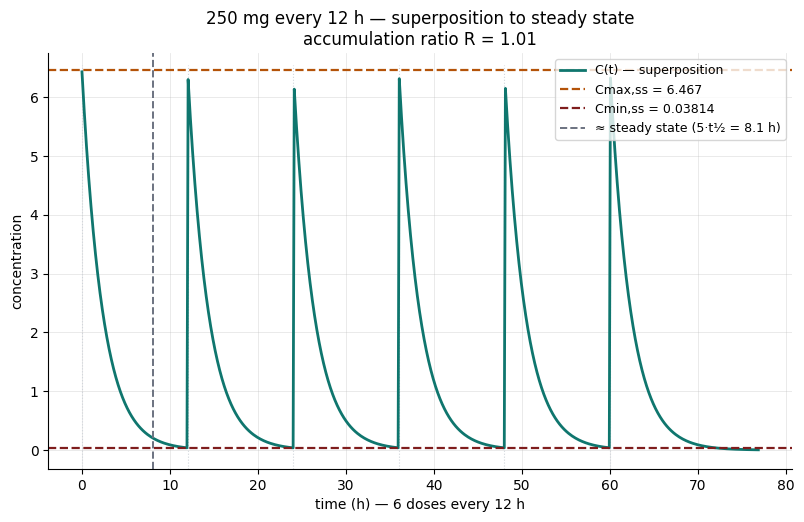

In [16]:
from pharmaml.viz import plot_dose_accumulation

# Six q12h doses of the demo drug: the superposition (grey ticks mark the
# dose times), the steady-state envelope, the 5·t½ marker.
fig_accumulation = plot_dose_accumulation(
    dose=250.0, tau=12.0, t_half=summary.half_life_terminal,
    vd=35.0, f=0.9, n_doses=6,
    title="250 mg every 12 h — superposition to steady state",
)


## 8 · PD — the Emax family

Pharmacodynamics in one parameterisation: effect rises toward `Emax` with
concentration, `EC50` marks the halfway point, and the Hill coefficient
bends the curve (steeper than 1 = switch-like). The inhibitory form runs
the same logic downward — baseline minus inhibition, `IC50` where the
effect is half the maximum — and `linear_effect` is the honest fallback
when the data has seen nothing but a straight line.

`ec50_for_target_effect` inverts the model: give it the effect you *want*
(80 % of Emax) and it returns the concentration that achieves it — target
concentration design in one call. `effect_table` renders the same model
as a ready-to-report table.


In [17]:
from pharmaml.pharma.pd import (
    emax_effect,
    inhibitory_emax_effect,
    linear_effect,
    sigmoid_emax_effect,
)

pd_grid = np.array([0.0, 5.0, 10.0, 20.0, 40.0, 80.0, 160.0])

pd_curves = pd.DataFrame(
    {
        "conc_ng_ml": pd_grid,
        "emax_hill1": emax_effect(pd_grid, e0=0.0, emax=100.0, ec50=20.0),
        "sigmoid_hill1_5": sigmoid_emax_effect(
            pd_grid, e0=0.0, emax=100.0, ec50=20.0, hill=1.5
        ),
        "inhibitory_ic50_10": inhibitory_emax_effect(
            pd_grid, e0=100.0, imax=80.0, ic50=10.0
        ),
        "linear_slope0_4": linear_effect(pd_grid, slope=0.4, intercept=5.0),
    }
)
pd_curves.round(2)


,conc_ng_ml,emax_hill1,sigmoid_hill1_5,inhibitory_ic50_10,linear_slope0_4
0,0.0,0.00,0.00,100.00,5.0
1,5.0,20.00,11.11,73.33,7.0
2,10.0,33.33,26.12,60.00,9.0
3,20.0,50.00,50.00,46.67,13.0
4,40.0,66.67,73.88,36.00,21.0
5,80.0,80.00,88.89,28.89,37.0
6,160.0,88.89,95.77,24.71,69.0


In [18]:
from pharmaml.pharma.pd import ec50_for_target_effect, effect_table

ec80 = ec50_for_target_effect(
    target_effect=80.0, ec50=20.0, e0=0.0, emax=100.0, hill=1.5
)
effect_at_ec80 = sigmoid_emax_effect(ec80, e0=0.0, emax=100.0, ec50=20.0, hill=1.5)
print(f"concentration for 80% of Emax:  {ec80:.2f} ng/mL")
print(f"reverse check, E at that conc:  {effect_at_ec80:.1f}%")

pd.DataFrame(effect_table(pd_grid, e0=0.0, emax=100.0, ec50=20.0, hill=1.5))


concentration for 80% of Emax:  50.40 ng/mL
reverse check, E at that conc:  80.0%


,concentration,effect
0,0.0,0.000000
1,5.0,11.111111
2,10.0,26.120387
3,20.0,50.000000
4,40.0,73.879613
5,80.0,88.888889
6,160.0,95.767629


## 9 · Dosage design

Target-concentration dosing: the maintenance dose keeps `CL·Css·τ/F` in
the body per interval, a loading dose fills the volume in one step
(`Vd·Css/F`), and the infusion rate is just `CL·Css`. For the patient's
size there are the classical scalings — per kilogram, per m² of body
surface (Mosteller), and the century-old pediatric rules of Clark and
Young.

The functions are pure math and deliberately unit-agnostic: feed them a
consistent unit system and the numbers line up (§11 converts between the
units). The pediatric rules are rules of thumb from an era before
population PK — keep them for cross-checks, not as the dosing authority.


In [19]:
from pharmaml.pharma.dosage import infusion_rate, loading_dose, maintenance_dose

TARGET_CSS, TAU = 15.0, 12.0    # ng/mL, every 12 h -- the design target

maintenance = maintenance_dose(cl, target_css=TARGET_CSS, tau=TAU, f=F)
loading = loading_dose(vd=35.0, target_concentration=TARGET_CSS, f=F)
infusion = infusion_rate(cl, target_css=TARGET_CSS)

print(f"maintenance dose  {maintenance:9.1f}  every {TAU:g} h   = CL·Css·τ/F")
print(f"loading dose      {loading:9.1f}              = Vd·Css/F")
print(f"infusion rate     {infusion:9.1f}  per h        = CL·Css")
print(f"\n(§6 identity check: rate/CL = "
      f"{iv_infusion_steady_state(infusion, cl):.2f} = Css, as designed)")


maintenance dose     2505.5  every 12 h   = CL·Css·τ/F
loading dose          583.3              = Vd·Css/F
infusion rate         187.9  per h        = CL·Css

(§6 identity check: rate/CL = 15.00 = Css, as designed)


In [20]:
from pharmaml.pharma.dosage import (
    bsa_mosteller,
    clarks_rule,
    dose_by_bsa,
    dose_by_weight,
    youngs_rule,
)

# One adult (170 cm, 58 kg) and one child (6 y, 44 lb / 20 kg) -- the
# numbers every clinical-pharmacy exam asks for.
size_frame = pd.DataFrame(
    {
        "rule": [
            "per kg (5 mg/kg × 58 kg)",
            "per m² (100 mg/m², BSA via Mosteller)",
            "Clark (44-lb child, 250 mg adult dose)",
            "Young (6-year-old, 250 mg adult dose)",
        ],
        "dose": [
            dose_by_weight(5.0, weight_kg=58.0),
            dose_by_bsa(100.0, height_cm=170.0, weight_kg=58.0),
            clarks_rule(child_weight_lb=44.0, adult_dose=250.0),
            youngs_rule(child_age_years=6.0, adult_dose=250.0),
        ],
    }
)
print(f"BSA (Mosteller, 170 cm / 58 kg): {bsa_mosteller(170, 58):.3f} m²")
size_frame.round(1)


BSA (Mosteller, 170 cm / 58 kg): 1.655 m²


,rule,dose
0,per kg (5 mg/kg × 58 kg),290.0
1,"per m² (100 mg/m², BSA via Mosteller)",165.5
2,"Clark (44-lb child, 250 mg adult dose)",73.3
3,"Young (6-year-old, 250 mg adult dose)",83.3


## 10 · Patient-specific adjustments

The §9 regimen assumed a standard patient; this one isn't her: 67 years,
58 kg, serum creatinine 1.4 mg/dL, female. Cockcroft-Gault puts her
creatinine clearance near 36 mL/min, and `renal_dose_adjustment` scales
the maintenance dose by `CrCl/100` — with a 25 % floor so the arithmetic
never quietly drops a renally-cleared drug to zero.

Then the loop that closes every real regimen: the trough comes back at
8 ng/mL against a 12 ng/mL target, and `tdm_trough_adjustment` rescales
the dose (linear kinetics assumed — trough scales with dose).


In [21]:
from pharmaml.pharma.dosage import renal_dose_adjustment
from pharmaml.pharma.pk import creatinine_clearance

PATIENT = {"age_years": 67, "weight_kg": 58, "serum_cr_mg_dl": 1.4, "sex": "female"}

crcl = creatinine_clearance(**PATIENT)
adjusted = renal_dose_adjustment(maintenance, current_creatinine_clearance=crcl)
floored = renal_dose_adjustment(maintenance, current_creatinine_clearance=10.0)

print(f"Cockcroft-Gault CrCl   {crcl:7.1f} mL/min")
print(f"maintenance dose       {maintenance:9.1f}")
print(f"renal-adjusted         {adjusted:9.1f}    (CrCl/100 scaling)")
print(f"severe case, CrCl 10   {floored:9.1f}    (hits the 25% floor)")


Cockcroft-Gault CrCl      35.7 mL/min
maintenance dose          2505.5
renal-adjusted             894.5    (CrCl/100 scaling)
severe case, CrCl 10       626.4    (hits the 25% floor)


In [22]:
from pharmaml.pharma.dosage import tdm_trough_adjustment

measured, target = 8.0, 12.0     # ng/mL troughs
new_dose = tdm_trough_adjustment(
    adjusted, measured_trough=measured, target_trough=target
)

print(f"TDM: trough {measured:g} -> {target:g} ng/mL")
print(f"     dose    {adjusted:9.1f} -> {new_dose:9.1f}    "
      f"(x{target / measured:.2f}, linear kinetics assumed)")


TDM: trough 8 -> 12 ng/mL
     dose        894.5 ->    1341.8    (x1.50, linear kinetics assumed)


## 11 · Units & molar mass

The pharma functions are unit-agnostic on purpose — the discipline lives
in one place instead: `UnitConverter` knows the mass, volume, amount,
molar-concentration and time scales (and refuses to cross dimensions,
the classic 1000-fold medication error), while `molar_mass` parses
chemical formulas, hydrates and parentheses groups.

Caffeine (C₈H₁₀N₄O₂) is the demo molecule: 194.19 g/mol, so the §1 dose
of 250 mg is a round 1.29 mmol.


In [23]:
from pharmaml.exceptions import UnitConversionError
from pharmaml.pharma.units import UnitConverter, molar_mass

caffeine = molar_mass("C8H10N4O2")

unit_frame = pd.DataFrame(
    [
        ("500 mg", "g", UnitConverter.convert(500, "mg", "g")),
        ("1 µM", "nM", UnitConverter.convert(1, "uM", "nM")),
        ("250 mg dose", "mmol (caffeine)",
         UnitConverter.convert(UnitConverter.convert(250, "mg", "g") / caffeine,
                               "mol", "mmol")),
    ],
    columns=["from", "to", "result"],
)
print(f"molar mass C8H10N4O2 (caffeine): {caffeine:.2f} g/mol")

# And the dimension guard -- mass to volume is refused, loudly:
try:
    UnitConverter.convert(500, "mg", "mL")
except UnitConversionError as exc:
    print(f"rejected: {exc}")

unit_frame


molar mass C8H10N4O2 (caffeine): 194.19 g/mol
rejected: cannot convert mass 'mg' to volume 'mL'


,from,to,result
0,500 mg,g,0.500000
1,1 µM,nM,1000.000000
2,250 mg dose,mmol (caffeine),1.287372


## 12 · Publish — the one-click visual bundle

The one command the spreadsheet workflow never had: figures + tables +
metrics into a self-contained `report.html` (figures embedded as data
URIs, zero external assets — open it in any browser) plus machine- and
human-readable exports of every table. `export_table` picks the format
from the file extension; `save_visual_bundle` does everything else.


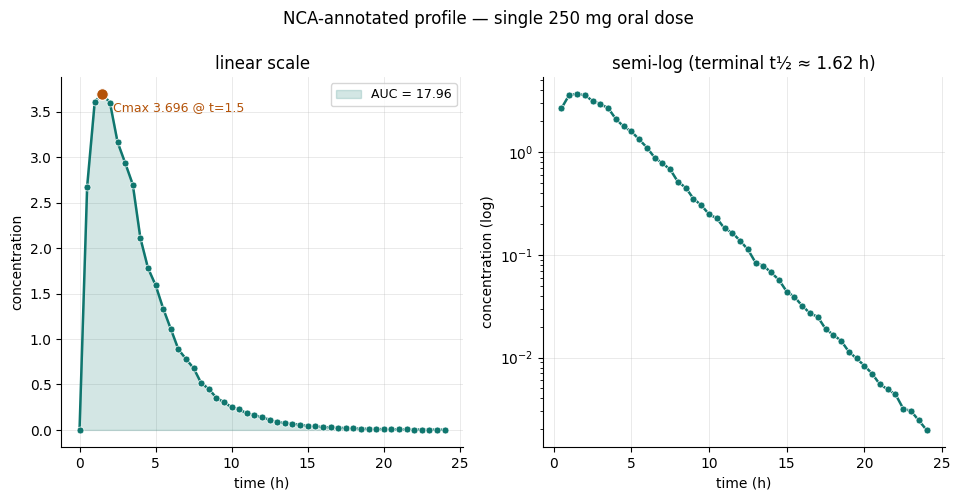

In [24]:
from pharmaml.viz import plot_concentration_profile

# The publish-grade profile: same curve as §2, now with the NCA summary
# feeding every annotation -- AUC shaded, Cmax/Tmax marked, terminal t½
# in the semi-log panel title.
fig_report = plot_concentration_profile(
    times, conc, summary=summary,
    title="NCA-annotated profile — single 250 mg oral dose",
)


In [25]:
from pharmaml.viz import export_table

REPORT = WORK / "report"

# The NCA table in every format a report could need:
exports = [
    export_table(nca_frame, REPORT / f"nca_summary.{ext}")
    for ext in ("csv", "tsv", "md", "json", "html")
]
[p.name for p in exports]


['nca_summary.csv',
 'nca_summary.tsv',
 'nca_summary.md',
 'nca_summary.json',
 'nca_summary.html']

In [26]:
from pharmaml.viz import save_visual_bundle

artifacts = save_visual_bundle(
    figures={
        "concentration_profile": fig_report,
        "dose_accumulation": fig_accumulation,
    },
    tables={
        "nca_summary": nca_frame,
        "pd_curves": pd_curves,
    },
    metrics=summary,
    out_dir=REPORT,
    title="PK/PD workflow — single oral dose analysis",
    subtitle=(f"NCA · {len(frame)} samples · CL {cl:.2f} L/h · "
              f"t½ {summary.half_life_terminal:.2f} h"),
    formats=("png", "svg"),
    close=True,    # figures already rendered inline above; free the memory
)
for path in artifacts:
    print(f"  {path.relative_to(WORK)}")


  report/report.html
  report/nca_summary.csv
  report/nca_summary.md
  report/pd_curves.csv
  report/pd_curves.md
  report/concentration_profile.png
  report/concentration_profile.svg
  report/dose_accumulation.png
  report/dose_accumulation.svg


In [27]:
# The self-contained report: open it in any browser — figures are embedded.
report_html = REPORT / "report.html"
size_kb = report_html.stat().st_size / 1024
print(f"{report_html}  ({size_kb:.0f} KB, zero external assets)")
print("First 3 lines:")
print("\n".join(report_html.read_text().splitlines()[:3]))


/tmp/pk_workflow__hy_4dun/report/report.html  (202 KB, zero external assets)
First 3 lines:
<!DOCTYPE html>
<html lang='en' data-theme='auto'>
<head>


## 13 · Recap

| Stage | One-liner |
|---|---|
| Import your profile | `read_table("profile.csv")` + `require_columns(frame, [...])` |
| Validate | `validate_concentration_series(times, conc)` |
| NCA | `nca_summary(times, conc)` → AUC/AUMC/MRT/Cmax/Tmax/t½ |
| AUC math | `auc_trapezoid(t, c, method="linear"\|"log")` |
| Half-life | `half_life(ke)` ↔ `elimination_rate_constant(t_half)` |
| Clearance & Vd | `clearance(dose, auc, f)` + `volume_of_distribution(cl, ke)` |
| Analytic 1-cmt | `oral_tmax(ka, ke)` / `oral_cmax(dose, ka, ke, vd, f)` |
| IV routes | `iv_bolus_concentration(c0, ke, t)` / `iv_infusion_steady_state(rate, cl)` |
| Accumulation | `accumulation_ratio(tau, t_half)` + `plot_dose_accumulation(...)` |
| PD | `sigmoid_emax_effect(c, e0, emax, ec50, hill)` / `ec50_for_target_effect(...)` |
| Dosage design | `maintenance_dose` / `loading_dose` / `infusion_rate` / `dose_by_bsa` |
| Patient adjustment | `creatinine_clearance(...)` → `renal_dose_adjustment` → `tdm_trough_adjustment` |
| Units | `UnitConverter.convert(500, "mg", "g")` / `molar_mass("C8H10N4O2")` |
| Publish | `save_visual_bundle(figures, tables, metrics, "report")` |

CLI equivalents:

```bash
pharmaml pharma pk   --data profile.csv --time time_h --conc conc_ng_ml --out nca.json
pharmaml pharma dose --cl 12.5 --vd 35 --target-css 15 --tau 12 --f 0.9
pharmaml data inspect --data profile.csv
```

The trilogy, complete: **ML** (a model from SMILES), **docking** (a campaign
from CSV + PDB), **PK/PD** (the pharma math around them) — none of which the
rar archive ever shipped.
